# Demo 2: Persistence: the goal encoding holds until the sub-goal is done

**Insight.** Once the LM commits to a sub-goal, the goal heads keep encoding it while the LM writes its
implementation, and hand over to the next sub-goal when the line is done. At the behavioral level, the LM also keeps
pursuing the sub-goal when a bad start is forced onto its line.

**Setup (A, temporal persistence).** A 4-sub-task Python function is prefilled up to `b =`, the pivot of the second
sub-task. The LM writes `b` and then, on its own, `c`, `d` and the `return`. At every generated token we sum what the
goal heads write (the *goal encoding*) and compare it with the encoding at the `b =` pivot. As a control, the same
with 122 random heads.

**Setup (B, obstacle persistence).** A 2-sub-task function where the line `b =` is force-started with a prefix the LM
cannot delete: a correct start (aligned), an ignorable stub (easy), or a misleading fragment (hard). An LM judge
(Claude) decides whether the LM still implements the sub-goal by working around the prefix (ADAPTED), gives in to it
(SUCCUMBED), or escapes or breaks the line.

**Paper.** §3.4 (`fig:temporal-retention`), App. `app:persistence:temporal` (`fig:retention-control`),
App. `app:persistence:obstacle` (`fig:obstacle-datatype`, `tab:obstacle-models`).

Needs one 80 GB GPU (Qwen2.5-Coder-32B-Instruct in bf16). The executed outputs are saved in this file.

**The setup** (schematics from the lab talk):

![Obstacle persistence: plant a misleading prefill and see whether the model recovers (App. K.2).](figures/02_obstacle_setup.png)

*Obstacle persistence: plant a misleading prefill and see whether the model recovers (App. K.2).*

In [1]:
# repo root = first parent dir that contains src/
import os, sys
_d = os.getcwd()
while _d != '/' and not os.path.isdir(os.path.join(_d, 'src')):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d); os.chdir(_d)
print('repo root:', _d)

# no progress bars: keeps tqdm / HF widget outputs out of the saved notebook
os.environ['TQDM_DISABLE'] = '1'
import functools, tqdm.std, tqdm.notebook, transformers, huggingface_hub
for _c in (tqdm.std.tqdm, tqdm.notebook.tqdm):   # tqdm.notebook ignores TQDM_DISABLE, so force disable=True
    _c.__init__ = functools.partialmethod(_c.__init__, disable=True)
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()      # no generation-config warnings
huggingface_hub.utils.disable_progress_bars()

# as in the paper's figures: source red, destination green, patched run purple
from typing import Literal
ide_theme: Literal['dark', 'light'] = 'dark'
if ide_theme == 'dark':   # light shades; the task-span fill reuses the text color
    SRC_C, DST_C, PAT_C = 'salmon1', 'sea_green3', 'plum2'
    SRC_BG, DST_BG      = SRC_C, DST_C
    PIVOT_BG            = 'bright_yellow'
else:                     # the paper's colors (Figure 5)
    SRC_C, DST_C, PAT_C = '#cc0000', '#38761d', '#5b277d'
    SRC_BG, DST_BG      = '#f4cccc', '#d9ead3'
    PIVOT_BG            = '#ffe6b2'

repo root: /disk/u/arnab/Codes/Projects/goals


In [2]:
CUDA     = '7'
MODEL    = 'Qwen/Qwen2.5-Coder-32B-Instruct'
SEED     = 1123

# Part A: temporal persistence
TP_DATATYPE = 'str'
TP_SUBTASKS = ['is_alnum', 'vowel_count', 'word_count', 'count_digits']   # the function's 4 sub-tasks, in order
TARGET_POS  = 1          # probe the 2nd sub-task (`b`); the 1st (`a`) is prefilled
CONTROL_SEED = 7         # draws the 122 random control heads

# Part B: obstacle persistence
OB_DATATYPE = 'list[int]'
OB_SUBTASK  = 'total_sum'   # "the sum of all values"
OB_PREFIX   = ' - 1 +'      # the hard obstacle forced after `b =`

os.environ['CUDA_VISIBLE_DEVICES'] = CUDA

## Load the model
Qwen2.5-Coder-32B-Instruct, its 122 goal heads, and 122 random heads from the later half of the LM (none of them goal
heads) as a control.

In [3]:
import random, torch
import numpy as np
import matplotlib.pyplot as plt
from rich.console import Console
from rich.table import Table
from rich.text import Text
from rich.markup import escape

from src.models import ModelandTokenizer
from src.utils import experiment_utils
from src.tokens import prepare_input
import src.nrgs.data as D
from src.goals import temporal_persistence as TP
from scripts.evaluation.ablation_common import random_heads_like
sys.path.insert(0, 'notebooks/fig_n_table_generators')
import figstyle as F; F.set_style()

console = Console(width=140, highlight=False)
torch.set_grad_enabled(False)
experiment_utils.set_seed(SEED)

mt = ModelandTokenizer(model_key=MODEL, dtype=torch.bfloat16, device_map={'': 0}, attn_implementation='eager')
goal_heads = TP.load_goal_heads(mt, MODEL.split('/')[-1])
ctrl_heads = random_heads_like(ablated=goal_heads, from_layer=mt.n_layer // 2, n_layer=mt.n_layer,
                               n_heads=mt.n_heads, exclude=goal_heads, rng=random.Random(CONTROL_SEED))
print(f'goal heads: {len(goal_heads)} | control heads: {len(ctrl_heads)} (overlap {len(set(goal_heads) & set(ctrl_heads))})')

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


goal heads: 122 | control heads: 122 (overlap 0)


## 1. Temporal persistence: the prompt
The task lists all four sub-tasks. The first is prefilled as a full line, and the prompt stops at the `=` of the
second, `b`: that `=` is the **pivot**.

In [4]:
def show_prompt(prompt, title, spans=(), bg=DST_BG, pivot=None):
    """The prompt from the user turn on: the given char spans on `bg`, the pivot char span highlighted, the rest dim."""
    start = prompt.index('<|im_start|>user')
    marks = sorted([(a, b_, f'black on {bg}') for a, b_ in spans] + ([(*pivot, f'bold black on {PIVOT_BG}')] if pivot else []))
    txt, i = Text(), start
    for a, b_, style in marks:
        txt.append(prompt[i:a], style='dim'); txt.append(prompt[a:b_], style=style); i = b_
    txt.append(prompt[i:], style='dim')
    console.rule(title); console.print(txt)

def desc_span(prompt, k, desc):                      # the "(k) description" line of the task list
    a = prompt.index(f'({k}) {desc}')
    return a, a + len(f'({k}) {desc}')

setups = D.multi_predicate_setups(TP_DATATYPE, n_conditions=list(TP.N_COND), n_samples=256, seed=SEED,
                                  naming='letters', src_lang='python', dst_lang='python')
inst = next(i for i in setups if [p.id for p in i._preds_for(i.src_frontier)] == TP_SUBTASKS)
preds = inst._preds_for(inst.src_frontier)
prompt, tv = TP.build_probe_prompt(mt, inst, preds, TARGET_POS)

t = Table(title='the four sub-tasks')
t.add_column('var'); t.add_column('sub-task'); t.add_column('in the prompt')
for k, p in enumerate(preds):
    st = 'prefilled' if k < TARGET_POS else (f'[bold {DST_C}]probed at its `=`[/]' if k == TARGET_POS else 'the LM writes it on its own')
    t.add_row(TP._letter(k), escape(p.description), st)
console.print(t)
show_prompt(prompt, 'the probe prompt', [desc_span(prompt, TARGET_POS + 1, preds[TARGET_POS].description)],
            pivot=(len(prompt) - 1, len(prompt)))

                                  the four sub-tasks                                  
┏━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ var ┃ sub-task                                       ┃ in the prompt               ┃
┡━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ a   │ whether every character is a letter or a digit │ prefilled                   │
│ b   │ the number of vowels                           │ probed at its `=`           │
│ c   │ the number of whitespace-separated words       │ the LM writes it on its own │
│ d   │ the number of digit characters                 │ the LM writes it on its own │
└─────┴────────────────────────────────────────────────┴─────────────────────────────┘

───────────────────────────────────────────────────────────── the probe prompt ─────────────────────────────────────────────────────────────

<|im_start|>user
Write a Python program that implements a function `func` which, given a string `s`, computes in sequential order:
(1) whether every character is a letter or a digit
(2) the number of vowels
(3) the number of whitespace-separated words
(4) the number of digit characters
<|im_end|>
<|im_start|>assistant
<code>
def func(s: str):
    a = s.isalnum()
    b =

## 2. Temporal persistence: the LM's code
A greedy rollout from the pivot. An LM judge (Claude) marks which tokens implement `b`; the later lines `c = ...` and
`d = ...` are found directly.

In [5]:
stub = lambda prompt: prompt.rsplit('\n', 1)[-1]          # the prefilled `    b =`

def show_run(title, color, prompt, gen, prefix='', verdict=None):
    console.rule(f'[bold {color}]{title}[/]')
    console.print(f'[bold]continuation:[/]\n[grey50]{escape(stub(prompt))}[/]'
                  + (f'[bold {SRC_C}]{escape(prefix)}[/]' if prefix else '') + f'[{color}]{escape(gen.rstrip())}[/]')
    if verdict: console.print(f'[bold]judge:[/] {verdict}')
    console.print()

full_text = TP.rollout_probe(mt, prompt)
gen = full_text[len(prompt):]
show_run('the LM run', DST_C, prompt, gen)

offs = TP._offsets(mt, full_text)
P = TP.prompt_boundary(mt, prompt, full_text)            # first generated token; the `b =` pivot is P-1
seg = TP.oracle_value_segment(prompt.split('<code>\n', 1)[-1], tv, preds[TARGET_POS].description, gen)
eq_tok, impl = TP.locate_value(offs, full_text, len(prompt), P, seg)

later = {}                                               # the later sub-tasks: their `=` pivot and their line
for k in range(TARGET_POS + 1, len(preds)):
    v = TP._letter(k)
    c0 = full_text.find(f'\n    {v} =', len(prompt))
    if c0 < 0:
        continue
    eq_c = full_text.index('=', c0)
    line_end = full_text.find('\n', eq_c); line_end = len(full_text) if line_end < 0 else line_end
    eqt = next(i for i, (a, b) in enumerate(offs) if a <= eq_c < b)
    later[v] = dict(eq=eqt, impl=TP._toks_in(offs, eq_c + 1, line_end))
print(f'implementation of {tv}: {len(impl)} tokens | later lines found: {", ".join(later)}')

──────────────────────────────────────────────────────────────── the LM run ────────────────────────────────────────────────────────────────

continuation:
    b = sum(1 for char in s if char.lower() in 'aeiou')
    c = len(s.split())
    d = sum(1 for char in s if char.isdigit())
    return a, b, c, d
</code>

implementation of b: 16 tokens | later lines found: c, d


## 3. Temporal persistence: the goal encoding at every token
For each generated token, the cosine between its goal encoding and the encoding at each sub-task's `=` pivot. With the
goal heads, the `b =` curve should stay high over `b`'s implementation and drop when the line ends, while the `c =`
and `d =` curves rise over their own lines: the encoding tracks which sub-goal is being implemented. With the control
heads, each curve peaks only at its own pivot (a vector always matches itself). The table averages each curve over
each implementation (bold: the sub-goal's own line).

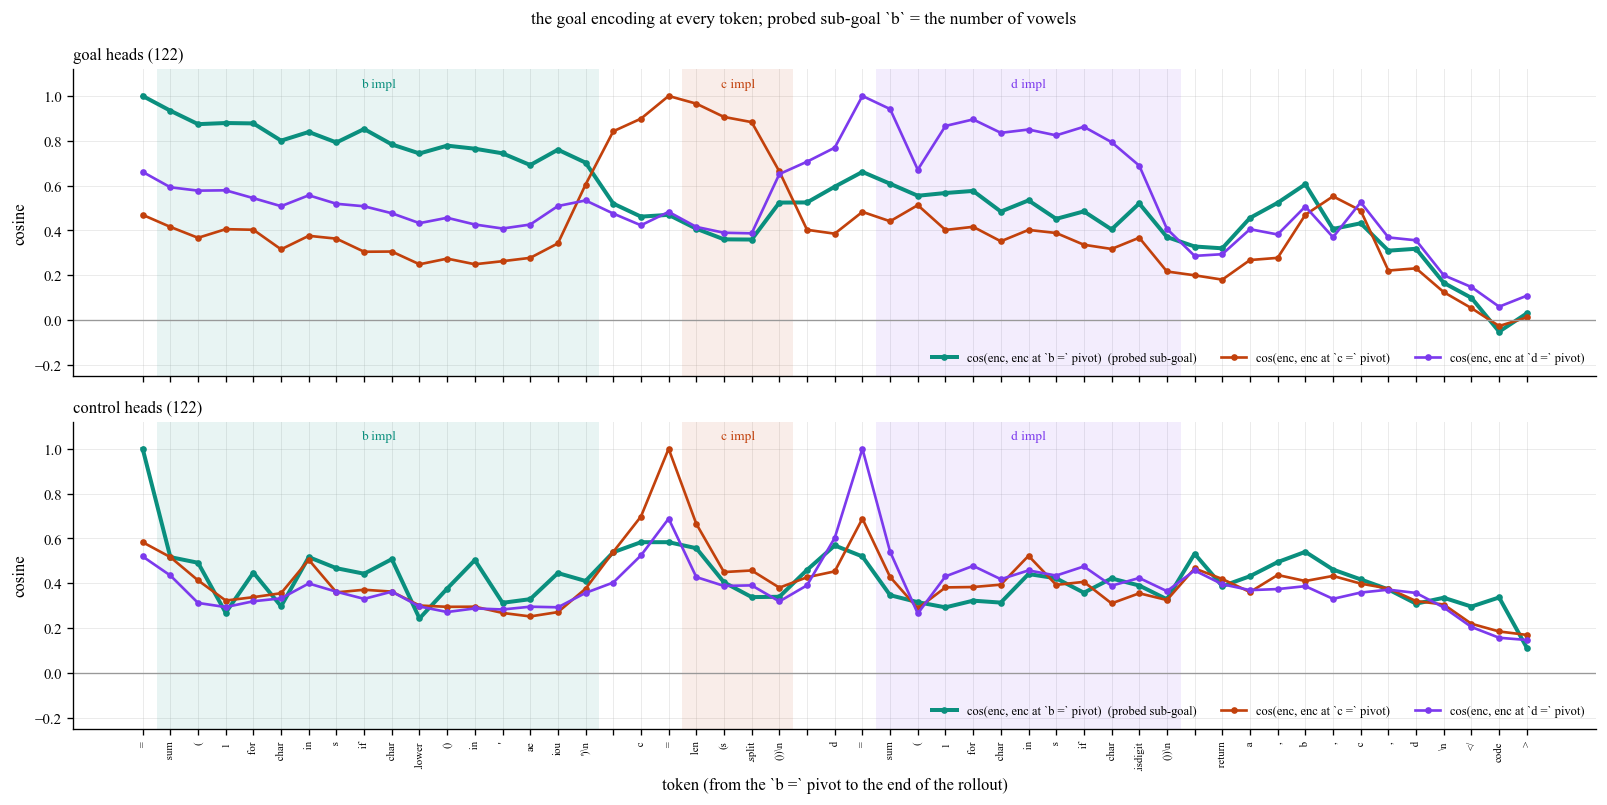

In [6]:
L = len(offs)
positions = list(range(eq_tok, L))
enc = {'goal': TP.goal_encoding(mt, full_text, positions, goal_heads),
       'control': TP.goal_encoding(mt, full_text, positions, ctrl_heads)}
idx = {p: i for i, p in enumerate(positions)}
pivots = {tv: eq_tok, **{v: d['eq'] for v, d in later.items()}}
spans = {tv: impl, **{v: d['impl'] for v, d in later.items()}}

def cos_to(E, p):
    U = E / E.norm(dim=-1, keepdim=True)
    return (U @ U[idx[p]]).numpy()

colors = {tv: F.TP_TEAL, **dict(zip(later, [F.TP_ORANGE, '#7c3aed']))}
fig, axes = plt.subplots(2, 1, figsize=(13.5, 6.8), sharex=True, sharey=True)
xs = np.arange(len(positions))
toks = [mt.tokenizer.decode([i]) for i in TP.prepare_input(prompts=full_text, tokenizer=mt)['input_ids'][0].tolist()]
for ax, (name, E) in zip(axes, enc.items()):
    for v, sp in spans.items():
        ax.axvspan(idx[sp[0]] - .5, idx[sp[-1]] + .5, color=colors[v], alpha=.09, lw=0)
        ax.text((idx[sp[0]] + idx[sp[-1]]) / 2, 1.04, f'{v} impl', ha='center', fontsize=8, color=colors[v])
    for v, p in pivots.items():
        lw = 2.4 if v == tv else 1.6
        ax.plot(xs, cos_to(E, p), color=colors[v], lw=lw, marker='o', ms=3,
                label=f'cos(enc, enc at `{v} =` pivot)' + ('  (probed sub-goal)' if v == tv else ''))
    ax.axhline(0, color='#999', lw=.8)
    ax.set_ylabel('cosine'); ax.set_ylim(-0.25, 1.12)
    ax.set_title(f'{name} heads ({len(goal_heads) if name == "goal" else len(ctrl_heads)})', fontsize=10, loc='left')
    ax.legend(fontsize=7.5, frameon=False, loc='lower right', ncol=3)
axes[-1].set_xticks(xs); axes[-1].set_xticklabels([repr(toks[p])[1:-1] for p in positions], rotation=90, fontsize=6.5)
axes[-1].set_xlabel('token (from the `b =` pivot to the end of the rollout)')
fig.suptitle(f'the goal encoding at every token; probed sub-goal `{tv}` = {preds[TARGET_POS].description}', fontsize=10.5)
fig.tight_layout(); plt.show()

In [7]:
t = Table(title='mean cosine with each pivot, over each implementation')
t.add_column('heads'); t.add_column('pivot')
for v in spans: t.add_column(f'{v} impl', justify='right')
for name, E in enc.items():
    for v, p in pivots.items():
        c = cos_to(E, p)
        cells_ = []
        for w, sp in spans.items():
            m = float(np.mean([c[idx[q]] for q in sp]))
            cells_.append(f'[bold]{m:.2f}[/]' if w == v else f'{m:.2f}')
        t.add_row(name, f'`{v} =`', *cells_)
console.print(t)

    mean cosine with each pivot, over each    
                implementation                
┏━━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ heads   ┃ pivot ┃ b impl ┃ c impl ┃ d impl ┃
┡━━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ goal    │ `b =` │   0.80 │   0.41 │   0.51 │
│ goal    │ `c =` │   0.34 │   0.85 │   0.38 │
│ goal    │ `d =` │   0.50 │   0.46 │   0.79 │
│ control │ `b =` │   0.41 │   0.41 │   0.36 │
│ control │ `c =` │   0.35 │   0.49 │   0.38 │
│ control │ `d =` │   0.33 │   0.38 │   0.42 │
└─────────┴───────┴────────┴────────┴────────┘

## 4. Obstacle persistence: a forced bad start
Two sub-tasks, the first prefilled; after `b =` we force a prefix (red) that the LM cannot delete, and let it
continue greedily. Every obstacle leaves a syntactic way out. No goal heads are involved: this is the behavioral side
of persistence.

In [8]:
from scripts.evaluation.obstacle_persistence_eval import build_obstacle_prompt, LEVELS, N_PER, MAX_NEW as OB_MAX_NEW
from scripts.evaluation.obstacle_persistence_prefills import OBSTACLE_PREFILLS
from scripts.evaluation.obstacle_persistence_judge import judge_adapts
from scripts.evaluation.eval_goalscope import greedy_continue

VERDICT_C = {'ADAPTED': DST_C, 'SUCCUMBED': SRC_C}

def run_obstacle(prefix):
    """The forced prompt, the LM's full continuation, and the judge's verdict on the `b =` line."""
    ob_prompt, target = build_obstacle_prompt(mt, OB_DATATYPE, OB_SUBTASK, prefix)
    g = greedy_continue(mt, **prepare_input(prompts=ob_prompt, tokenizer=mt), max_new_tokens=OB_MAX_NEW)
    rhs = (prefix + g).split('\n')[0].strip()              # the judged `b =` line, as in the eval
    return ob_prompt[:len(ob_prompt) - len(prefix)], target, g, judge_adapts(target.description, prefix, rhs)

ob_prompt, target, g, v = run_obstacle(OB_PREFIX)
k = 2                                                     # the target is the 2nd listed sub-task
show_prompt(ob_prompt, 'the obstacle prompt', [desc_span(ob_prompt, k, target.description)], pivot=(len(ob_prompt) - 1, len(ob_prompt)))
c = VERDICT_C.get(v['verdict'], 'grey50')
show_run(f'forced prefix {OB_PREFIX!r}', DST_C, ob_prompt, g, prefix=OB_PREFIX,
         verdict=f"[bold {c}]{v['verdict']}[/] ({escape(v['rationale'])})")

─────────────────────────────────────────────────────────── the obstacle prompt ────────────────────────────────────────────────────────────

<|im_start|>user
Write a Python program that implements a function `func` which, given a list of integers `nums`, computes:
(1) the number of positive values
(2) the sum of all values
<|im_end|>
<|im_start|>assistant
<code>
def func(nums: list[int]):
    a = sum(1 for x in nums if x > 0)
    b =

────────────────────────────────────────────────────────── forced prefix ' - 1 +' ──────────────────────────────────────────────────────────

continuation:
    b = - 1 + sum(nums) + 1
    return a, b
</code>

judge: ADAPTED (The expression `-1 + sum(nums) + 1` simplifies to `sum(nums)`, correctly computing the sum of all values while incorporating
the forced prefix.)

## 5. Obstacle persistence: all three levels for this sub-task
The prefixes the paper uses for this sub-task (up to four per level), each with the LM's `b =` line and the judge's
verdict.

In [9]:
spec = OBSTACLE_PREFILLS[OB_DATATYPE][OB_SUBTASK]
t = Table(title=f'"{escape(target.description)}" under forced prefixes', show_lines=True)
t.add_column('level'); t.add_column('forced prefix'); t.add_column('the LM\'s line (b = ...)', max_width=70); t.add_column('verdict')
for lvl in LEVELS:
    for prefix in spec[lvl][:N_PER]:
        _, _, g_, v_ = run_obstacle(prefix)
        line = (prefix + g_).split('\n')[0]
        t.add_row(lvl, escape(repr(prefix)), f'[bold {SRC_C}]{escape(prefix)}[/][{DST_C}]{escape(line[len(prefix):])}[/]',
                  f"[{VERDICT_C.get(v_['verdict'], 'grey50')}]{v_['verdict']}[/]")
console.print(t)

                   "the sum of all values" under forced prefixes                    
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ level   ┃ forced prefix   ┃ the LM's line (b = ...)                  ┃ verdict   ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ aligned │ ' sum(nums'     │  sum(nums)                               │ ADAPTED   │
├─────────┼─────────────────┼──────────────────────────────────────────┼───────────┤
│ easy    │ ' 0 + '         │  0 + 0j                                  │ SUCCUMBED │
├─────────┼─────────────────┼──────────────────────────────────────────┼───────────┤
│ easy    │ ' ('            │  (sum(nums))                             │ ADAPTED   │
├─────────┼─────────────────┼──────────────────────────────────────────┼───────────┤
│ easy    │ ' (('           │  ((sum(nums),))                          │ BROKEN    │
├─────────┼─────────────────┼──────────────────────────────────────────┼───────────┤
│ hard    │ ' ((max(nums))' │  ((max(nums)) + (min(nums))) * len(nums) │ SUCCUMBED │
├─────────┼─────────────────┼──────────────────────────────────────────┼───────────┤
│ hard    │ ' - 1 +'        │  - 1 + sum(nums) + 1                     │ ADAPTED   │
└─────────┴─────────────────┴──────────────────────────────────────────┴───────────┘

## What to expect
<img src="figures/02_temporal_persistence_results.png" width="400" alt="Temporal persistence of the sub-goal encoding (Figure 3 in the paper)">

**Temporal persistence.** With the goal heads, the encoding should stay close to the `b =` pivot while `b` is
written and hand over to `c` and `d` on their lines; the control heads show no such hand-over. Pooled over 4 datatypes
and both languages, the encoding stays closer to the pivot for the same sub-goal (even in a different function and
language) than for a different sub-goal in the same function, all through the implementation; the gap shrinks
towards its end. See §3.4 and Figure 3 in the paper; App. K.1 (Figure 29) adds the control heads.

<img src="figures/02_obstacle_persistence_results.png" width="400" alt="Obstacle robustness of Qwen2.5-Coder-32B-Instruct by datatype (Figure 30 in the paper)">

**Obstacle persistence.** Under the hard prefix `- 1 +`, the LM should still compute the sum and cancel the forced
`- 1` (ADAPTED). Across 409 trials, Qwen2.5-Coder-32B-Instruct adapts to 97% of aligned, 63% of easy and 15% of hard
obstacles. See App. K.2 (Figure 30, Table 14), which compares seven models.